In [1]:
# 필요한 외부 패키지: numpy, pandas, matplotlib, scikit-learn
# 설치가 필요하면 터미널에서 실행: python -m pip install numpy pandas matplotlib scikit-learn
# 이 노트북은 Jupyter Notebook이나 VS Code의 노트북 실행 환경에서 위에서부터 실행합니다.
# 설치 명령은 안내용 주석입니다. 이 셀을 실행해도 자동으로 설치하지 않습니다.
#
# [공통 준비 블록] 데이터 읽기와 그림을 그리는 함수
# 노트북 파일이 있는 폴더 아래에 data_sets 폴더를 만들고 다음 세 파일을 넣습니다.
# ./data_sets/spherical_6_2.csv : 300개 점, 정답 묶음 6개
# ./data_sets/3_spiral.csv     : 312개 점, 정답 묶음 3개
# ./data_sets/jain.csv        : 373개 점, 정답 묶음 2개
# 원래 파일 이름인 3-spiral.csv는 사용하지 않고, 바꾼 이름인 3_spiral.csv를 사용합니다.
# 데이터 출처: https://github.com/milaan9/Clustering-Datasets/tree/master/02.%20Synthetic
# CSV는 원본 ARFF의 x, y, class 값을 그대로 옮긴 파일입니다.
#
# [강의자료 확인]
# Lecture9_Clustering.pdf의 PDF 43~46쪽은 single, complete, average를 설명합니다.
# PDF 51쪽의 나무 그림 예제는 average, PDF 53쪽의 군집화 예제는 complete입니다.
# 이 노트북은 강의의 PDF 53쪽 실습과 같은 완전 연결법 complete를 사용합니다.
# 두 묶음 사이에서 가장 멀리 떨어진 점 쌍의 거리를 구합니다.
# 이 거리가 가장 작은 두 묶음을 고르고, 한 묶음으로 합치는 일을 반복합니다.
# 패키지 사용 근거: PDF 25~28쪽, 51쪽, 53쪽, 66쪽의 코드 예제입니다.
# 위쪽 화면에 표시되는 슬라이드 번호와 PDF의 실제 쪽 번호는 다를 수 있습니다.
#
# [실험 공통 조건]
# class는 데이터가 원래 어떤 묶음인지 알려 주는 비교용 정답입니다.
# 알고리즘에는 x, y만 넣고 class는 넣지 않습니다.
# 정답을 아는 예제이므로 K-Means와 계층적 군집화의 묶음 수를 6개 또는 3개로 정합니다.
# 실제 정답이 없는 자료에서는 묶음 수를 따로 고민해야 합니다.
# 좌표를 줄이거나 늘리지 않고 원본 그대로 사용합니다. eps도 원본 좌표의 거리입니다.
# 그림은 왼쪽이 정답 묶음, 오른쪽이 알고리즘이 만든 묶음입니다.
# 묶음 번호와 색은 이름표일 뿐입니다. 색이 달라도 같은 점들끼리 묶였으면 맞는 결과입니다.
# 그림의 영어 표시는 한글 글꼴이 없는 컴퓨터에서도 글자가 깨지지 않도록 사용했습니다.
# Original groups는 정답 묶음, Group은 묶음, Noise는 어디에도 묶이지 않은 점입니다.

import numpy as np  # 점들의 묶음 번호를 정리할 때 사용합니다.
import pandas as pd  # CSV 파일을 표로 읽을 때 사용합니다.
import matplotlib.pyplot as plt  # 점들의 위치를 그림으로 그릴 때 사용합니다.
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN  # 세 군집화 방법을 가져옵니다.

# 파일은 이 노트북과 같은 폴더를 기준으로 찾습니다.
spherical = pd.read_csv("./data_sets/spherical_6_2.csv")  # 둥근 묶음 6개를 읽습니다.
spiral = pd.read_csv("./data_sets/3_spiral.csv")  # 나선 모양의 묶음 3개를 읽습니다.
jain = pd.read_csv("./data_sets/jain.csv")  # 빽빽한 정도가 다른 묶음 2개를 읽습니다.

# 빠진 값이나 열 이름 문제가 있으면 실험을 진행하기 전에 알려 줍니다.
for name, data in [("spherical_6_2", spherical), ("3_spiral", spiral), ("jain", jain)]:
    assert list(data.columns) == ["x", "y", "class"], "CSV 열 이름은 x,y,class여야 합니다."
    assert not data.isna().any().any(), "CSV에 비어 있는 값이 있습니다."
    print(f"{name}: 점 {len(data)}개 / 정답 묶음 {data['class'].nunique()}개")  # 읽은 내용을 확인합니다.


# 같은 그림 코드를 여섯 번 쓰지 않도록 공통 함수로 묶습니다.
def show_result(data, labels, title, centers=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)  # 비교할 그림 두 개를 만듭니다.
    panels = [(axes[0], data["class"].to_numpy(), "Original groups"),
              (axes[1], labels, title)]  # 왼쪽에는 정답, 오른쪽에는 실행 결과를 넣습니다.
    for ax, groups, panel_title in panels:
        color_index = 0  # 일반 묶음의 색을 차례로 고를 번호입니다.
        for group in np.unique(groups):  # 묶음 하나씩 꺼내 그림에 표시합니다.
            selected = groups == group  # 지금 묶음에 속한 점만 고릅니다.
            if group == -1:  # DBSCAN이 어디에도 묶지 못한 점의 번호는 -1입니다.
                ax.scatter(data.loc[selected, "x"], data.loc[selected, "y"],
                           color="black", marker="x", s=28, label="Noise")  # 잡음은 검은 X로 표시합니다.
            else:
                ax.scatter(data.loc[selected, "x"], data.loc[selected, "y"],
                           color=plt.cm.tab10(color_index % 10), s=18,
                           label=f"Group {color_index + 1}")  # 같은 묶음은 같은 색으로 표시합니다.
                color_index += 1  # 다음 묶음에는 다음 색을 사용합니다.
        ax.set_title(panel_title)  # 어떤 결과인지 제목을 붙입니다.
        ax.set_xlabel("x")  # 가로축은 원본 x좌표입니다.
        ax.set_ylabel("y")  # 세로축은 원본 y좌표입니다.
        ax.set_aspect("equal", adjustable="box")  # 가로와 세로의 거리 비율을 같게 유지합니다.
        ax.grid(alpha=0.15)  # 위치를 읽기 쉽도록 연한 줄을 넣습니다.
        ax.legend(fontsize=8, loc="best")  # 색과 묶음의 관계를 표시합니다.
    if centers is not None:  # K-Means 결과라면 각 묶음의 중심도 표시합니다.
        axes[1].scatter(centers[:, 0], centers[:, 1], c="black", marker="+",
                        s=170, linewidths=2, label="Centers")  # 검은 +가 중심입니다.
        axes[1].legend(fontsize=8, loc="best")  # 중심에 대한 설명도 함께 표시합니다.
    fig.tight_layout()  # 제목과 축 이름이 겹치지 않도록 간격을 맞춥니다.
    plt.show()  # 완성한 그림을 노트북에 표시합니다.


# DBSCAN의 -1은 일반 묶음이 아니므로 묶음 수에서 제외합니다.
def show_counts(labels):
    group_count = len(np.unique(labels[labels != -1]))  # 잡음을 빼고 묶음 수를 셉니다.
    noise_count = int(np.sum(labels == -1))  # 어디에도 묶이지 않은 점을 셉니다.
    print(f"만들어진 묶음: {group_count}개 / 잡음: {noise_count}개")  # 결과를 짧게 보여 줍니다.

print("준비 완료. 아래의 실험 1~6을 차례로 실행하세요.")  # 이 셀은 준비만 하고 실험은 아래에서 합니다.

spherical_6_2: 점 300개 / 정답 묶음 6개
3_spiral: 점 312개 / 정답 묶음 3개
jain: 점 373개 / 정답 묶음 2개
준비 완료. 아래의 실험 1~6을 차례로 실행하세요.


실험 1 | K-Means | spherical_6_2.csv | 묶음 수=6, 시작 시도=10, 고정값=42
만들어진 묶음: 6개 / 잡음: 0개


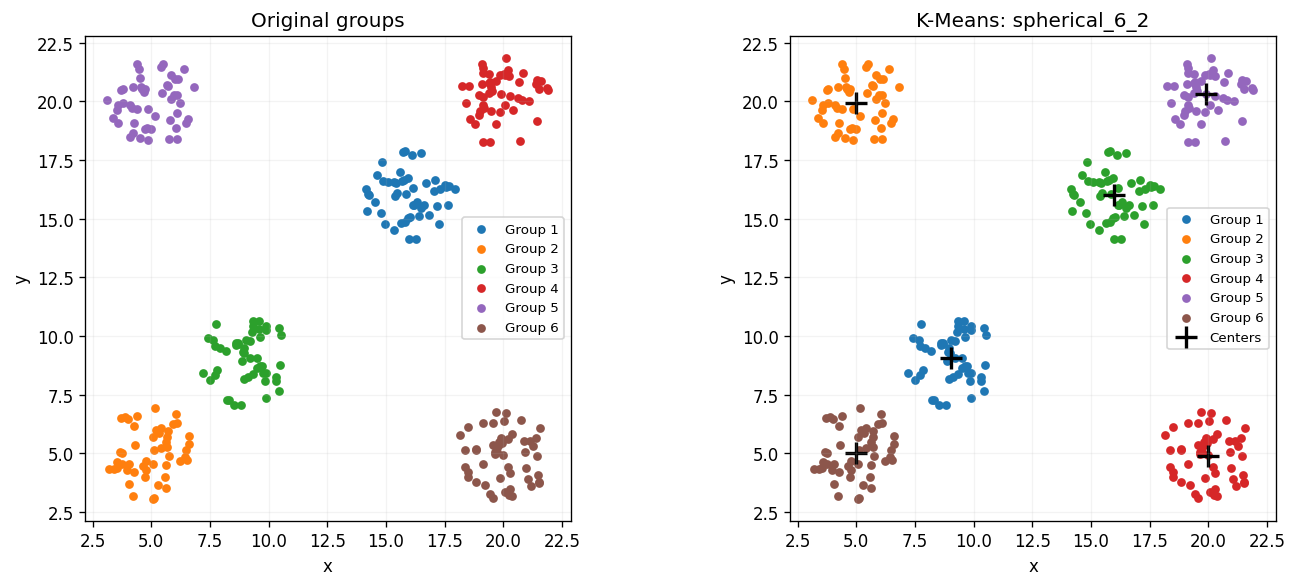

결과: 원래의 둥근 점 무리 6개를 각각 하나의 묶음으로 나눴습니다.
이유: 같은 무리의 점들은 자기 무리 중심에 가깝고, 다른 무리 중심에서는 멉니다.
강점: 떨어진 둥근 묶음을 찾기 쉽고, 각 묶음의 평균 위치도 알 수 있습니다.
주의: 묶음 수 6개는 미리 알려 줬습니다. 이 방법이 스스로 알아낸 수는 아닙니다.


In [2]:
# [실험 1] K-Means가 잘 묶는 사례: spherical_6_2.csv
# 선택 이유: 둥근 점 무리 6개가 떨어져 있어 중심을 기준으로 나누기 좋습니다.
# K-Means는 점을 가까운 중심에 넣고, 묶음의 평균 위치로 중심을 옮기는 일을 반복합니다.
# n_clusters=6: 이 예제에서는 묶음 6개를 만듭니다.
# n_init=10: 시작 중심을 다르게 해서 10번 시도한 뒤 가장 나은 결과를 고릅니다.
# random_state=42: 다시 실행했을 때 같은 시작 조건을 사용합니다.

X = spherical[["x", "y"]]  # 정답 class를 빼고 좌표만 입력으로 고릅니다.
model = KMeans(n_clusters=6, random_state=42, n_init=10).fit(X)  # K-Means를 실행합니다.
labels = model.labels_  # 각 점에 붙은 묶음 번호를 꺼냅니다.
print("실험 1 | K-Means | spherical_6_2.csv | 묶음 수=6, 시작 시도=10, 고정값=42")  # 실험 조건입니다.
show_counts(labels)  # 몇 개로 묶였는지 확인합니다.
show_result(spherical, labels, "K-Means: spherical_6_2", model.cluster_centers_)  # 정답과 중심을 비교합니다.
print("결과: 원래의 둥근 점 무리 6개를 각각 하나의 묶음으로 나눴습니다.")  # 실제 그림에서 확인할 부분입니다.
print("이유: 같은 무리의 점들은 자기 무리 중심에 가깝고, 다른 무리 중심에서는 멉니다.")  # 잘된 이유입니다.
print("강점: 떨어진 둥근 묶음을 찾기 쉽고, 각 묶음의 평균 위치도 알 수 있습니다.")  # 이 사례가 보여 주는 장점입니다.
print("주의: 묶음 수 6개는 미리 알려 줬습니다. 이 방법이 스스로 알아낸 수는 아닙니다.")  # 결과의 조건도 밝힙니다.

실험 2 | K-Means | 3_spiral.csv | 묶음 수=3, 시작 시도=10, 고정값=42
만들어진 묶음: 3개 / 잡음: 0개


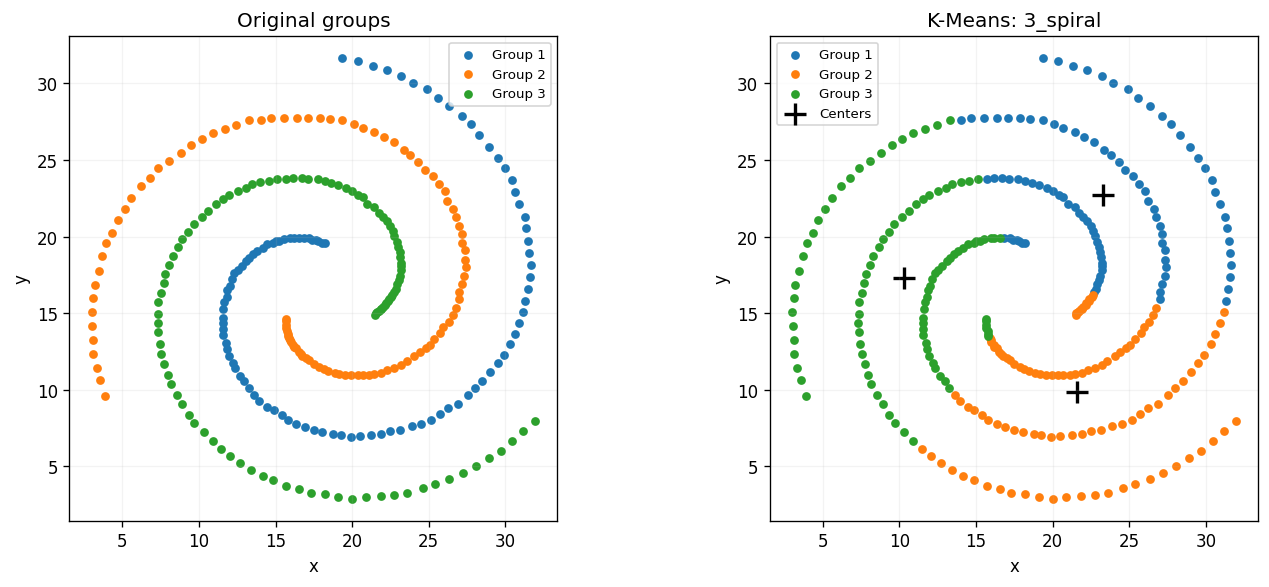

결과: 묶음은 3개지만, 하나의 나선이 여러 묶음으로 잘리고 다른 나선의 점과 섞였습니다.
이유: 나선을 따라 이어지는 관계보다 중심과의 거리를 기준으로 점을 나누기 때문입니다.
약점: 길게 휘거나 서로 감긴 모양은 중심 하나로 표현하기 어렵습니다.
판단: 묶음 수만 세지 않고, 나선 하나 전체가 같은 묶음으로 남았는지 봐야 합니다.


In [3]:
# [실험 2] K-Means가 잘 묶지 못하는 사례: 3_spiral.csv
# 선택 이유: 나선 하나가 길게 이어져 있어 중심 하나까지의 거리만으로 구분하기 어렵습니다.
# 묶음 수를 정답과 같은 3개로 알려 줘도 실패하는지 확인합니다.

X = spiral[["x", "y"]]  # 나선형 데이터의 좌표만 고릅니다.
model = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)  # 시작 조건은 실험 1과 같게 합니다.
labels = model.labels_  # 각 점이 어느 묶음에 들어갔는지 꺼냅니다.
print("실험 2 | K-Means | 3_spiral.csv | 묶음 수=3, 시작 시도=10, 고정값=42")  # 실험 조건입니다.
show_counts(labels)  # 묶음 수가 맞아도 내용까지 맞는 것은 아닙니다.
show_result(spiral, labels, "K-Means: 3_spiral", model.cluster_centers_)  # 나선이 끊기는 모습을 봅니다.
print("결과: 묶음은 3개지만, 하나의 나선이 여러 묶음으로 잘리고 다른 나선의 점과 섞였습니다.")  # 실패한 모습입니다.
print("이유: 나선을 따라 이어지는 관계보다 중심과의 거리를 기준으로 점을 나누기 때문입니다.")  # 실패한 원리입니다.
print("약점: 길게 휘거나 서로 감긴 모양은 중심 하나로 표현하기 어렵습니다.")  # 이 사례가 보여 주는 한계입니다.
print("판단: 묶음 수만 세지 않고, 나선 하나 전체가 같은 묶음으로 남았는지 봐야 합니다.")  # 그림을 읽는 기준입니다.

실험 3 | 계층적 완전 연결법 | spherical_6_2.csv | 묶음 수=6, linkage=complete
만들어진 묶음: 6개 / 잡음: 0개


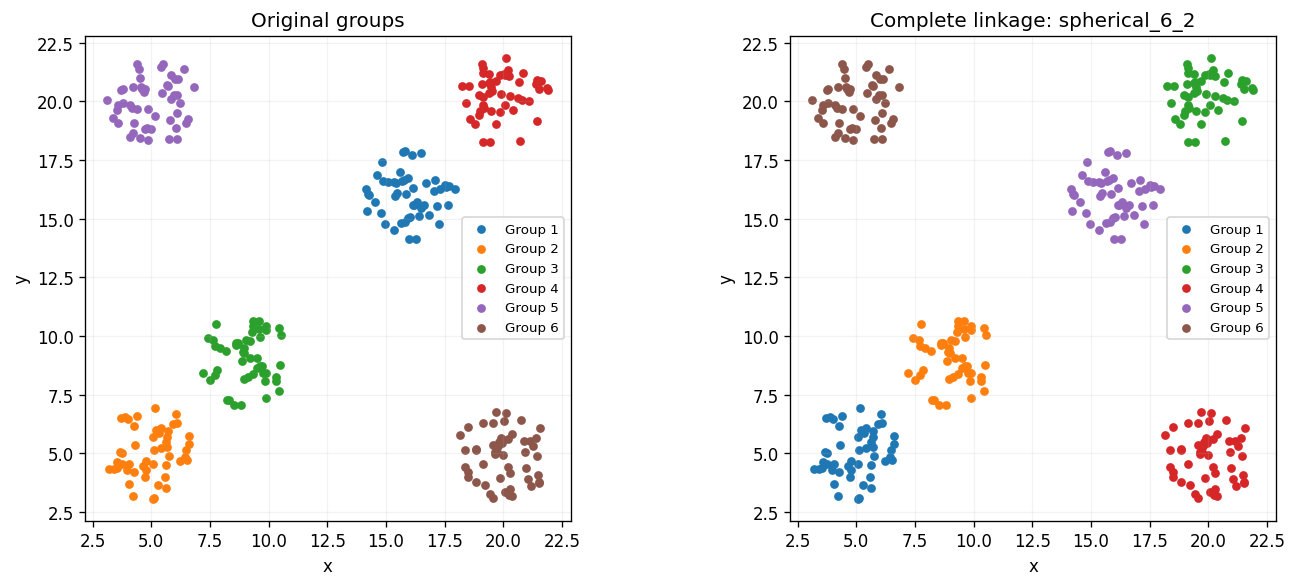

결과: 원래의 둥근 점 무리 6개를 각각 하나로 묶었습니다.
이유: 다른 무리와 합칠 때보다 같은 무리 안에서 합칠 때 가장 먼 점 사이의 거리가 짧습니다.
강점: 묶음의 전체 폭을 살펴 합치므로, 서로 떨어진 조밀한 무리를 찾기 좋습니다.
주의: 여기서는 최종 묶음만 그렸습니다. 합치는 과정 전체를 보려면 나무 모양 그림이 필요합니다.


In [4]:
# [실험 3] 계층적 완전 연결법이 잘 묶는 사례: spherical_6_2.csv
# 처음에는 점 하나가 묶음 하나입니다. 작은 묶음들을 차례로 합칩니다.
# 완전 연결법은 두 묶음 사이에서 가장 멀리 떨어진 점 쌍의 거리를 구합니다.
# 이 거리가 가장 작은 두 묶음을 고르고, 하나로 합치는 일을 반복합니다.
# n_clusters=6: 최종적으로 묶음 6개가 남는 지점의 결과를 가져옵니다.
# linkage="complete": 강의의 PDF 53쪽 실습과 같은 완전 연결법을 사용합니다.

X = spherical[["x", "y"]]  # 정답을 제외한 좌표만 넣습니다.
model = AgglomerativeClustering(n_clusters=6, linkage="complete").fit(X)  # 강의의 완전 연결법을 실행합니다.
labels = model.labels_  # 최종 묶음 번호를 꺼냅니다.
print("실험 3 | 계층적 완전 연결법 | spherical_6_2.csv | 묶음 수=6, linkage=complete")  # 실험 조건입니다.
show_counts(labels)  # 묶음 수를 확인합니다.
show_result(spherical, labels, "Complete linkage: spherical_6_2")  # 정답 묶음과 나란히 비교합니다.
print("결과: 원래의 둥근 점 무리 6개를 각각 하나로 묶었습니다.")  # 실제 실행 결과입니다.
print("이유: 다른 무리와 합칠 때보다 같은 무리 안에서 합칠 때 가장 먼 점 사이의 거리가 짧습니다.")  # 잘된 이유입니다.
print("강점: 묶음의 전체 폭을 살펴 합치므로, 서로 떨어진 조밀한 무리를 찾기 좋습니다.")  # 이 사례의 장점입니다.
print("주의: 여기서는 최종 묶음만 그렸습니다. 합치는 과정 전체를 보려면 나무 모양 그림이 필요합니다.")  # 그림의 범위입니다.

실험 4 | 계층적 완전 연결법 | 3_spiral.csv | 묶음 수=3, linkage=complete
만들어진 묶음: 3개 / 잡음: 0개


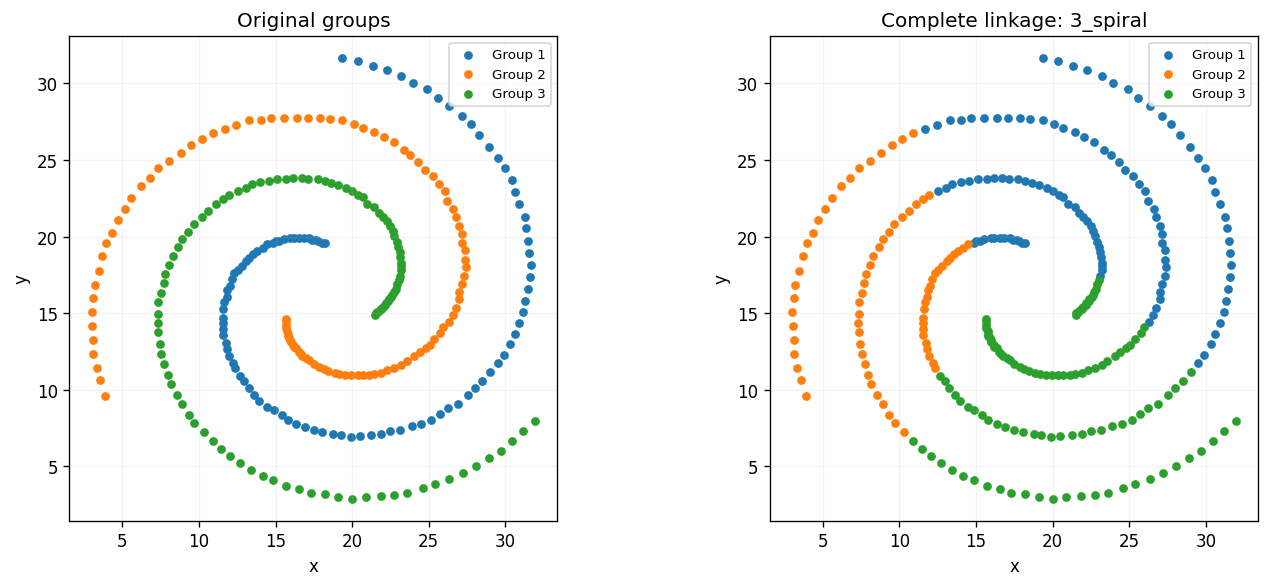

결과: 하나의 나선이 여러 묶음으로 나뉘고, 다른 나선의 일부와 같은 묶음에 들어갔습니다.
이유: 나선이 이어진 모양보다 묶음 사이에서 가장 먼 점들의 거리를 보고 합치기 때문입니다.
약점: 길게 휘어진 무리는 여러 조각으로 나눌 수 있고, 한 번 합친 묶음을 나중에 다시 쪼개지 않습니다.
범위: 이 설명은 완전 연결법에 대한 것입니다. single이나 average는 결과가 다를 수 있습니다.


In [5]:
# [실험 4] 계층적 완전 연결법이 잘 묶지 못하는 사례: 3_spiral.csv
# 선택 이유: 나선 하나는 길게 휘어 있어, 같은 나선의 양 끝도 멀리 떨어질 수 있습니다.
# 가장 먼 점 사이의 거리를 사용하는 기준이 나선 전체를 유지하는 데 불리한지 확인합니다.
# 묶음 수는 정답과 같은 3개로 정합니다.
# 이 결과를 모든 계층적 군집화 방법의 실패로 해석하면 안 됩니다.
# 강의의 단일 연결법 single은 가까운 점을 따라 이어져 나선을 잘 찾을 수도 있습니다.

X = spiral[["x", "y"]]  # 나선의 좌표만 입력으로 사용합니다.
model = AgglomerativeClustering(n_clusters=3, linkage="complete").fit(X)  # 실험 3과 같은 완전 연결법입니다.
labels = model.labels_  # 만들어진 묶음 번호를 꺼냅니다.
print("실험 4 | 계층적 완전 연결법 | 3_spiral.csv | 묶음 수=3, linkage=complete")  # 실험 조건입니다.
show_counts(labels)  # 수가 맞더라도 모양이 맞는지 함께 확인합니다.
show_result(spiral, labels, "Complete linkage: 3_spiral")  # 나선이 끊기고 섞이는 부분을 확인합니다.
print("결과: 하나의 나선이 여러 묶음으로 나뉘고, 다른 나선의 일부와 같은 묶음에 들어갔습니다.")  # 관찰한 실패입니다.
print("이유: 나선이 이어진 모양보다 묶음 사이에서 가장 먼 점들의 거리를 보고 합치기 때문입니다.")  # 실패한 원리입니다.
print("약점: 길게 휘어진 무리는 여러 조각으로 나눌 수 있고, 한 번 합친 묶음을 나중에 다시 쪼개지 않습니다.")  # 방법의 한계입니다.
print("범위: 이 설명은 완전 연결법에 대한 것입니다. single이나 average는 결과가 다를 수 있습니다.")  # 과도한 일반화를 피합니다.

실험 5 | DBSCAN | 3_spiral.csv | eps=1.5, min_samples=3
만들어진 묶음: 3개 / 잡음: 0개


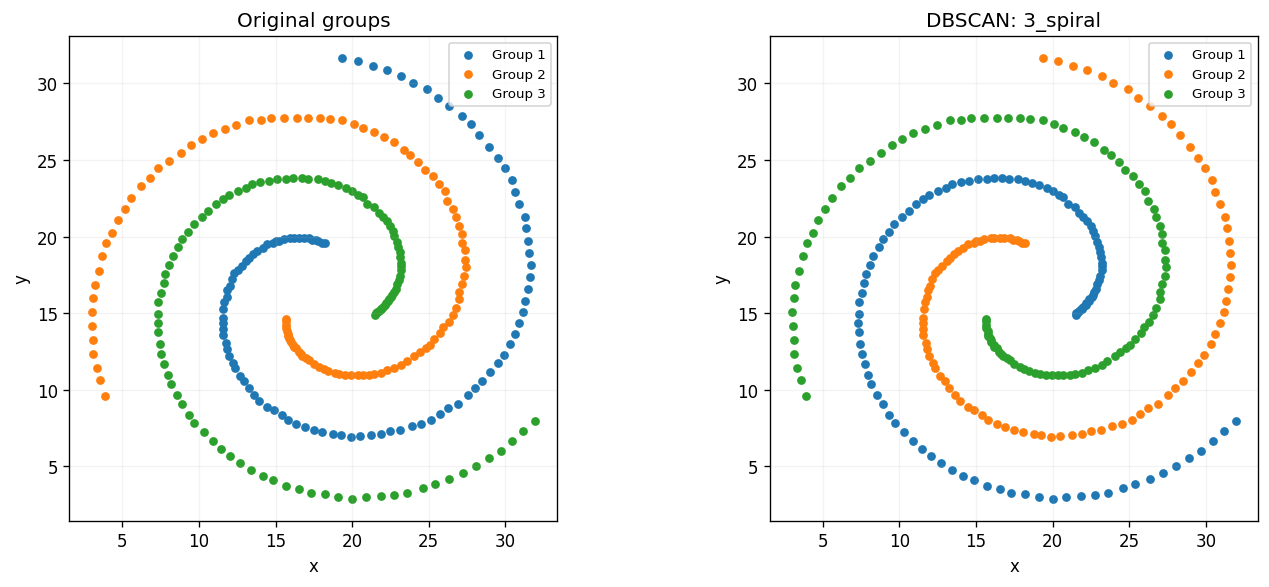

결과: 잡음 없이 나선 3개를 각각 하나의 묶음으로 찾았습니다.
이유: 중심까지의 거리 대신 가까운 점들의 연결을 따라 나선 끝까지 묶을 수 있습니다.
강점: 둥글지 않은 모양도 찾을 수 있고, 묶음 수를 미리 지정하지 않아도 됩니다.
주의: 아무 값이나 넣어도 되는 것은 아닙니다. 이 좌표 크기에 맞는 eps가 필요합니다.


In [6]:
# [실험 5] DBSCAN이 잘 묶는 사례: 3_spiral.csv
# 가까운 점이 충분히 모인 곳에서 시작해, 주변 점을 따라 묶음을 넓혀 갑니다.
# eps=1.5: 거리가 1.5 이하인 점을 이웃으로 봅니다.
# min_samples=3: 자기 자신을 포함해 이웃이 3개 이상이면 주변으로 묶음을 넓힐 수 있습니다.
# 선택 이유: 나선 안의 점들은 이어져 있지만, 서로 다른 나선 사이에는 틈이 있습니다.

X = spiral[["x", "y"]]  # 좌표만 사용합니다.
model = DBSCAN(eps=1.5, min_samples=3).fit(X)  # 묶음 수를 미리 알려 주지 않고 실행합니다.
labels = model.labels_  # 묶음 번호와 잡음 번호 -1을 꺼냅니다.
print("실험 5 | DBSCAN | 3_spiral.csv | eps=1.5, min_samples=3")  # 실험 조건입니다.
show_counts(labels)  # 정답을 알려 주지 않아도 묶음 3개가 나오는지 확인합니다.
show_result(spiral, labels, "DBSCAN: 3_spiral")  # 나선 하나가 한 색으로 이어지는지 확인합니다.
print("결과: 잡음 없이 나선 3개를 각각 하나의 묶음으로 찾았습니다.")  # 실제 실행 결과입니다.
print("이유: 중심까지의 거리 대신 가까운 점들의 연결을 따라 나선 끝까지 묶을 수 있습니다.")  # 잘된 원리입니다.
print("강점: 둥글지 않은 모양도 찾을 수 있고, 묶음 수를 미리 지정하지 않아도 됩니다.")  # 이 사례가 보여 주는 장점입니다.
print("주의: 아무 값이나 넣어도 되는 것은 아닙니다. 이 좌표 크기에 맞는 eps가 필요합니다.")  # 성공 조건입니다.

실험 6 | DBSCAN | jain.csv | eps=2.0, min_samples=5
만들어진 묶음: 5개 / 잡음: 20개


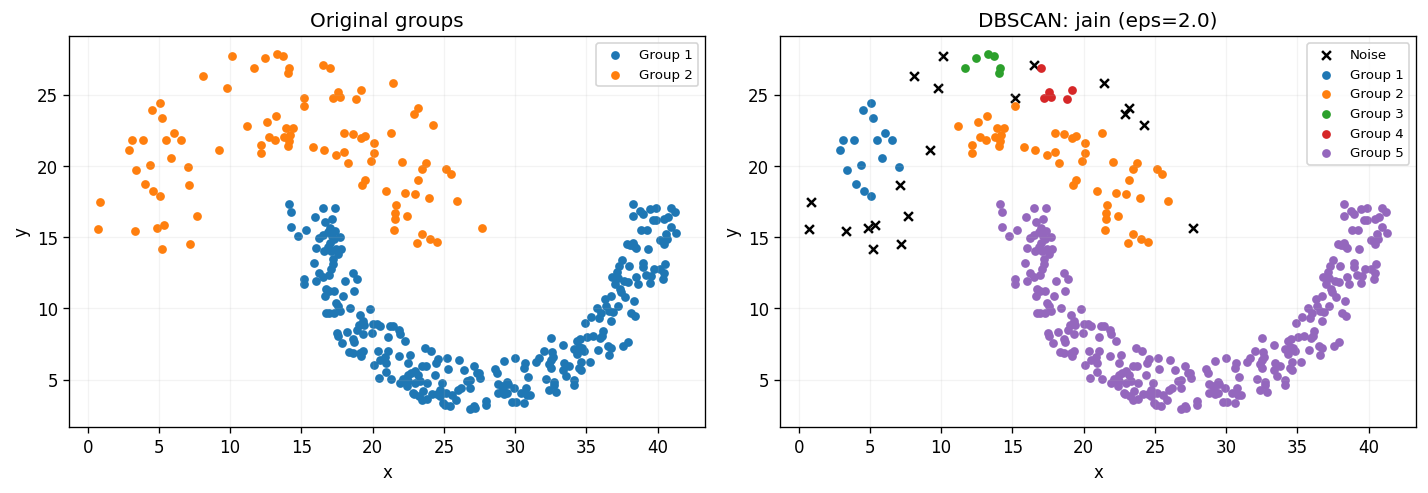

결과: 정답 묶음은 2개지만, 묶음 5개와 잡음 20개가 만들어졌습니다.
이유: 성긴 부분에서는 이웃이 부족해 연결이 끊어지거나 잡음으로 빠집니다.
약점: 빽빽한 정도가 다른 무리에 하나의 거리 기준을 함께 맞추기 어렵습니다.

거리 변경 비교 (min_samples=5 고정)
 eps  묶음 수  잡음 수
 2.0     5    20
 2.5     3     5
 3.0     1     1
해석: eps=2.5에서는 3개로 나뉘고, 3.0에서는 서로 다른 무리가 1개로 합쳐집니다.
결론: 작은 거리에서는 무리가 끊기고, 큰 거리에서는 다른 무리까지 이어질 수 있습니다.
범위: 여기서 확인한 설정의 한계이며, 모든 설정에서 반드시 실패한다는 뜻은 아닙니다.


In [7]:
# [실험 6] DBSCAN이 잘 묶지 못하는 사례: jain.csv
# 선택 이유: 한쪽은 점들이 빽빽하고, 다른 쪽은 점들이 비교적 성기게 놓여 있습니다.
# eps와 min_samples는 전체 데이터에 같은 값이 적용됩니다.
# eps=2.0, min_samples=5에서 두 묶음을 온전히 되찾는지 확인합니다.
# 잡음은 검은 X로 그립니다. -1도 일반 묶음 하나로 세지 않도록 주의합니다.

X = jain[["x", "y"]]  # 빽빽한 정도가 다른 데이터의 좌표만 사용합니다.
model = DBSCAN(eps=2.0, min_samples=5).fit(X)  # 우선 이 조건의 결과를 그림으로 확인합니다.
labels = model.labels_  # 최종 묶음과 잡음 번호를 꺼냅니다.
print("실험 6 | DBSCAN | jain.csv | eps=2.0, min_samples=5")  # 실험 조건입니다.
show_counts(labels)  # 정답은 2개인데 묶음은 5개, 잡음은 20개로 나옵니다.
show_result(jain, labels, "DBSCAN: jain (eps=2.0)")  # 성긴 무리가 조각나는 부분을 봅니다.
print("결과: 정답 묶음은 2개지만, 묶음 5개와 잡음 20개가 만들어졌습니다.")  # 실패를 구체적으로 설명합니다.
print("이유: 성긴 부분에서는 이웃이 부족해 연결이 끊어지거나 잡음으로 빠집니다.")  # 실패한 원리입니다.
print("약점: 빽빽한 정도가 다른 무리에 하나의 거리 기준을 함께 맞추기 어렵습니다.")  # 이 사례의 한계입니다.

# 거리만 키우면 해결되는지 표로 추가 확인합니다. 여섯 번째 실험 안의 매개변수 비교입니다.
# min_samples는 5로 고정해, eps를 바꾼 효과만 비교합니다.
rows = []  # 거리별 결과를 담을 빈 목록입니다.
for radius in [2.0, 2.5, 3.0]:  # 작은 거리부터 조금씩 늘려 봅니다.
    trial = DBSCAN(eps=radius, min_samples=5).fit(X)  # 같은 데이터에 거리만 바꿔 실행합니다.
    trial_labels = trial.labels_  # 이번 실행에서 나온 묶음 번호입니다.
    rows.append({"eps": radius,
                 "묶음 수": len(np.unique(trial_labels[trial_labels != -1])),
                 "잡음 수": int(np.sum(trial_labels == -1))})  # 잡음을 빼고 묶음 수를 셉니다.
print("\n거리 변경 비교 (min_samples=5 고정)")  # 아래 표의 비교 조건입니다.
print(pd.DataFrame(rows).to_string(index=False))  # 표를 간단한 글자로 출력합니다.
print("해석: eps=2.5에서는 3개로 나뉘고, 3.0에서는 서로 다른 무리가 1개로 합쳐집니다.")  # 실제 비교 결과입니다.
print("결론: 작은 거리에서는 무리가 끊기고, 큰 거리에서는 다른 무리까지 이어질 수 있습니다.")  # 값 조정의 어려움입니다.
print("범위: 여기서 확인한 설정의 한계이며, 모든 설정에서 반드시 실패한다는 뜻은 아닙니다.")  # 실험 범위를 정확히 밝힙니다.